In [1]:
import pandas as pd 
import numpy as np

import warnings
warnings.filterwarnings('ignore')

In [2]:
import os

curr_dir = os.path.basename(os.getcwd())
if curr_dir == "notebooks":
    os.chdir("..")

print(os.getcwd())

e:\project_archive\student-dropout-enrolled-graduate-rate-prediction


In [4]:
from utils.io import (
    load_csv,
    load_numpy
)

from utils.load_config import load_config

ModuleNotFoundError: No module named 'joblib'

In [4]:
config = load_config()

2026-10-09 18:53:55,465 | utils.load_config | DEBUG | config file loaded.


In [5]:
X_train = load_csv(path=config.data_paths.X_train_path)
y_train = load_numpy(path=config.data_paths.y_train_path)

2026-10-09 18:53:57,687 | utils.io | INFO | Loaded CSV: data\processed\X_train.csv
2026-10-09 18:53:57,689 | utils.io | INFO | Loaded NumPy array: data\processed\y_train.npy


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    stratify=y_train,
    test_size=0.2,
    random_state=43
)

In [7]:
X_train.shape

(2831, 36)

In [8]:
len(y_val)

708

In [8]:
print("y_train distribution")
print(np.bincount(y_train))

print("y_test distribution")
print(np.bincount(y_val))

y_train distribution
[ 910  508 1413]
y_test distribution
[227 127 354]


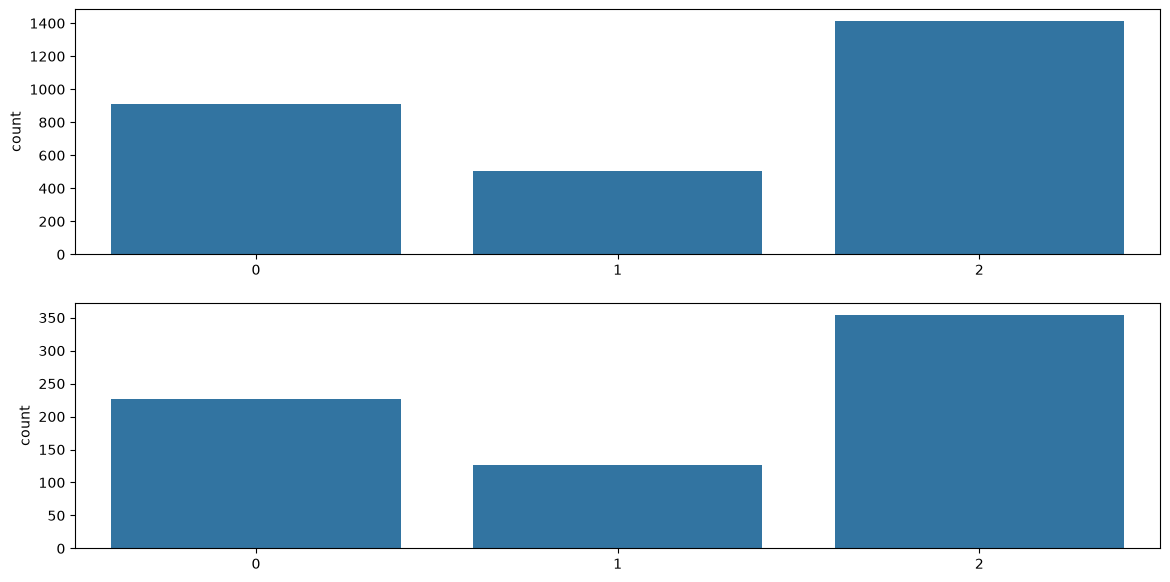

In [9]:
import matplotlib.pyplot as plt 
import seaborn as sns

fig, axes = plt.subplots(2,1, figsize=(14,7))
sns.countplot(x=y_train, ax=axes[0])   
sns.countplot(x=y_val,   ax=axes[1])

plt.show()

In [10]:
from sklearn.model_selection import  (
    StratifiedKFold,
    cross_validate
)

In [12]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
                max_iter=1000,
            class_weight="balanced",
)

In [11]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    model,
    X_train,
    y_train,
    cv=skf,
    scoring=[
        "accuracy",
        "f1_macro",
        "precision_macro",
        "recall_macro"
    ] 
    
)

NameError: name 'model' is not defined

In [14]:
print(scores["test_accuracy"])
print(scores["test_f1_macro"])

[0.67548501 0.68021201 0.72084806 0.68727915 0.68727915]
[0.63021801 0.64696438 0.68354652 0.64109723 0.64377561]


In [15]:
np.mean(scores["test_accuracy"]).item()

0.6902206766753292

In [16]:
for metric, score in scores.items():
    print(metric, score)

fit_time [1.24099517 2.54672289 1.4358809  1.43281388 1.44687438]
score_time [0.01081443 0.01356196 0.01011109 0.01140714 0.00956726]
test_accuracy [0.67548501 0.68021201 0.72084806 0.68727915 0.68727915]
test_f1_macro [0.63021801 0.64696438 0.68354652 0.64109723 0.64377561]
test_precision_macro [0.65046502 0.6641004  0.69243264 0.64472847 0.66908685]
test_recall_macro [0.64123692 0.66002451 0.69305649 0.64764584 0.65351366]


In [12]:
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

In [13]:
# INTERGATE MLFLOW
import mlflow 

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("SO-Phase1-Baseline")

<Experiment: artifact_location='mlflow-artifacts:/3', creation_time=1789994026302, effective_trace_archival_retention=None, experiment_id='3', last_update_time=1789994026302, lifecycle_stage='active', name='SO-Phase1-Baseline', tags={}, trace_location=None, workspace='default'>

In [14]:
models = {
        "logistic_regression": LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
        ),

        "random_forest": RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
        ),

        "hist_gradient_boosting": (
            HistGradientBoostingClassifier(
                random_state=42,
            )
        ),

        "xgboost": XGBClassifier(
            n_estimators=300,
            random_state=42,
            eval_metric="mlogloss",
            n_jobs=-1,
        ),

        "lightgbm": LGBMClassifier(
            n_estimators=300,
            random_state=42,
            verbosity=-1,
            n_jobs=-1,
        ),

        "catboost": CatBoostClassifier(
            iterations=300,
            verbose=False,
            random_seed=42,
        ),
    }

In [15]:
import yaml 

with open("config/models.yaml", "r") as f:
    model_config = yaml.safe_load(f)


In [16]:
display(model_config)

{'models': {'random_forest': {'class': 'RandomForestClassifier',
   'module': 'sklearn.ensemble',
   'params': {'random_state': 42, 'n_jobs': -1}},
  'logistic_regression': {'class': 'LogisticRegression',
   'module': 'sklearn.linear_model',
   'params': {'random_state': 42, 'max_iter': 1000}},
  'xgboost': {'class': 'XGBClassifier',
   'module': 'xgboost',
   'params': {'random_state': 42, 'n_jobs': -1, 'eval_metric': 'mlogloss'}},
  'lightgbm': {'class': 'LGBMClassifier',
   'module': 'lightgbm',
   'params': {'random_state': 42, 'n_jobs': -1, 'verbosity': -1}},
  'catboost': {'class': 'CatBoostClassifier',
   'module': 'catboost',
   'params': {'random_seed': 42, 'verbose': 0}}}}

In [26]:
rf_config = model_config["models"]["random_forest"]
display(rf_config)    

{'class': 'RandomForestClassifier',
 'module': 'sklearn.ensemble',
 'params': {'random_state': 42, 'n_jobs': -1}}

In [27]:
from sklearn.ensemble import RandomForestClassifier 

rf = RandomForestClassifier(
    **rf_config["params"]
)

print(type(rf))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [61]:
import importlib

def initialize_model(model_name, model_config):
    config = model_config["models"][model_name]

    module = importlib.import_module(config["module"])
    model_class = getattr(module, config["class"])

    model = model_class(**config.get("params", {}))

    return model


In [59]:
rf = initialize_model("random_forest", model_config=model_config)
print(type(rf))

{'class': 'RandomForestClassifier', 'module': 'sklearn.ensemble', 'params': {'random_state': 42, 'n_jobs': -1}}
<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [30]:
skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=43
)

In [31]:
for model_name in model_config["models"]:

    with mlflow.start_run(run_name=model_name):

        # Model
        model = initialize_model(
            model_name=model_name,
            model_config=model_config
        )

        # Log model metadata
        mlflow.log_param("model_name", model_name)
        mlflow.log_param("cv", "StratifiedKFold")
        mlflow.log_param("n_splits", 5)
        mlflow.log_param("random_state", 43)

        # Log model parameters
        mlflow.log_params({
            k: str(v)
            for k, v in model.get_params().items()
        })

        # Cross-validation
        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=skf,
            scoring=[
                "accuracy",
                "f1_macro"
            ]
        )

        # Metrics
        mlflow.log_metrics({
            "mean_fit_time": np.mean(
                scores["fit_time"]
            ).item(),

            "mean_accuracy": np.mean(
                scores["test_accuracy"]
            ).item(),

            "std_accuracy": np.std(
                scores["test_accuracy"]
            ).item(),

            "mean_f1_macro": np.mean(
                scores["test_f1_macro"]
            ).item(),

            "std_f1_macro": np.std(
                scores["test_f1_macro"]
            ).item(),
        })

🏃 View run random_forest at: http://localhost:5000/#/experiments/3/runs/a8f1b740d4e14ad1a24a7d156216cfa9
🧪 View experiment at: http://localhost:5000/#/experiments/3


RestException: INVALID_PARAMETER_VALUE: Changing param values is not allowed. Params were already logged='[{'key': 'random_state', 'old_value': '43', 'new_value': '42'}]' for run ID='a8f1b740d4e14ad1a24a7d156216cfa9'.

In [32]:
# CRITERION

criterion = {
    "mean_f1_macro": 0.70,
    "mean_fit_time": 1.5,
    "std_f1_macro": 0.70
}

In [39]:
import datetime
import mlflow

timeframe = datetime.timedelta(days=5)
cutoff_time = datetime.datetime.now() - timeframe
cutoff_timestamp_ms = int(cutoff_time.timestamp() * 1000)

filter_phase1_models = mlflow.search_runs(
    experiment_ids=["3"],
    filter_string=(
        f"metrics.mean_fit_time < {criterion['mean_fit_time']} AND "
        f"metrics.mean_f1_macro > {criterion['mean_f1_macro']} AND "
        f"attributes.start_time > {cutoff_timestamp_ms}"
    ),
    max_results=1,
)


In [38]:
import datetime 

timeframe = datetime.timedelta(days=5)
print(timeframe)
cutoff_time = datetime.datetime.now() - timeframe
print(cutoff_time)

print(int(cutoff_time.timestamp()*1000))

5 days, 0:00:00
2026-10-04 19:04:37.774050
1791120877774


In [40]:
filter_phase1_models

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.std_f1_macro,metrics.std_accuracy,metrics.mean_fit_time,metrics.mean_f1_macro,metrics.mean_accuracy,params.model_name,params.random_state,params.n_splits,params.cv,tags.mlflow.user,tags.mlflow.source.name,tags.mlflow.runName,tags.mlflow.source.type
0,a8c7fa112f834a2f868b803e14d89941,3,FINISHED,mlflow-artifacts:/3/a8c7fa112f834a2f868b803e14...,2026-10-05 08:29:57.934000+00:00,2026-10-05 08:30:02.803000+00:00,0.010514,0.008026,0.835122,0.710166,0.76333,random_forest,43,5,StratifiedKFold,harshal-kusalkar,09_test_codes.ipynb,random_forest,NOTEBOOK


In [55]:
best_model = filter_phase1_models["params.model_name"][0]

In [43]:
import yaml 

with open("config/tune.yaml") as f:
    tune = yaml.safe_load(f)

In [44]:
display(tune)

{'models': {'logistic_regression': {'class': 'LogisticRegression',
   'module': 'sklearn.linear_model',
   'params': {'C': [0.1, 1.0, 10.0],
    'solver': ['lbfgs'],
    'class_weight': ['balanced']}},
  'random_forest': {'class': 'RandomForestClassifier',
   'module': 'sklearn.ensemble',
   'params': {'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced']}},
  'hist_gradient_boosting': {'params': {'learning_rate': [0.05, 0.1],
    'max_iter': [100, 200],
    'max_leaf_nodes': [15, 31],
    'l2_regularization': [0.0, 1.0]}},
  'xgboost': {'class': 'XGBClassifier',
   'module': 'xgboost',
   'params': {'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]}},
  'lightgbm': {'class': 'LGBMClassifier',
   'module': 'lightgbm',
   'params': {'n_estimators': [100, 200, 300],
    'l

In [47]:
model = tune["models"]["random_forest"]

print(model)

{'class': 'RandomForestClassifier', 'module': 'sklearn.ensemble', 'params': {'n_estimators': [100, 200, 300], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5], 'min_samples_leaf': [1, 2], 'class_weight': ['balanced']}}


In [50]:
model["class"]

'RandomForestClassifier'

In [51]:
model["module"]

'sklearn.ensemble'

In [58]:
model = initialize_model("random_forest", tune)
print(type(model))

{'class': 'RandomForestClassifier', 'module': 'sklearn.ensemble', 'params': {'n_estimators': [100, 200, 300], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5], 'min_samples_leaf': [1, 2], 'class_weight': ['balanced']}}
<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [62]:
rf = initialize_model(model_name=best_model, model_config=tune)

print(type(rf))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


HYPERPARAM-TUNING

In [ ]:
# Load tuning params

import yaml  

with open("config/tune.yaml", mode="r") as f:
    tune_config = yaml.safe_load(f)


display(tune_config)

In [67]:
model = tune_config["models"][best_model]
search_space = model["params"]

display(search_space)

{'n_estimators': {'type': 'int', 'low': 100, 'high': 400, 'step': 100},
 'max_depth': {'type': 'categorical', 'choices': [None, 10, 20, 30]},
 'class_weight': {'type': 'categorical', 'choices': ['balanced', None]}}

In [74]:
# load params

def suggest_params(trial, search_space):

    params = {}

    for name, spec in search_space.items():
        param_type = spec["type"]

        if param_type == "categorical":
            params[name] = trial.suggest_categorical(
                name, 
                spec["choices"],
            )

        elif param_type == "int":
            params[name] = trial.suggest_int(
                  name, 
                  spec["low"], 
                  spec["high"],
                  step=spec.get("step", 1), 
                  log=spec.get("log", False),
            )

        elif param_type == "float":
            params[name] = trial.suggest_float(
                name, 
                spec["low"],
                spec["high"],
                step=spec.get("step", 1),
                log=spec.get("log", False),
            )
        else:
            raise ValueError(
                f"Unsupported param type: {param_type}"
            )

    return params

In [76]:
# Define objective function

import optuna 
from sklearn.base import clone 
from sklearn.model_selection import cross_val_score, StratifiedKFold
def objective(
        trial, 
        model, 
        X,
        y,
        cv,
        scoring="f1_macro",
):

    # sample params from yaml
    params = suggest_params(trial, search_space)

    # Clone the selected baseline model
    candidate = clone(model)

    # set params inside model
    candidate.set_params(**params)

    # Evaluate using cross-validation
    score = cross_val_score(
        candidate,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,

    )


    return score.mean()

In [78]:
import yaml 

with open("config/tune.yaml") as f:
    tune_config = yaml.safe_load(f)

best_model_name = filter_phase1_models["params.model_name"][0]

model_config = tune_config["models"][best_model]
search_space = model_config["params"]

model = initialize_model(model_name=best_model_name, model_config=tune_config)

cv = StratifiedKFold(
    n_splits=5,  
    shuffle=True, 
    random_state=43,

)

study = optuna.create_study(
    direction="maximize",
    study_name=f"{best_model}_tuning"
)

study.optimize(
    lambda trial: objective(
        trial=trial, 
        model=model,
        X=X_train, 
        y=y_train, 
        cv=cv,     

    ), 
    n_trials=30, 

)


print("Selected model:", best_model_name)
print("Best CV Macro F1:", study.best_value)
print("Best parameters:", study.best_params)

[I 2026-10-09 23:26:10,952] A new study created in memory with name: random_forest_tuning
[I 2026-10-09 23:26:13,298] Trial 0 finished with value: 0.7100175717239022 and parameters: {'n_estimators': 400, 'max_depth': 10, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.7100175717239022.
[I 2026-10-09 23:26:14,451] Trial 1 finished with value: 0.7099754531084067 and parameters: {'n_estimators': 200, 'max_depth': 10, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.7100175717239022.
[I 2026-10-09 23:26:15,123] Trial 2 finished with value: 0.7035532662045896 and parameters: {'n_estimators': 100, 'max_depth': None, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.7100175717239022.
[I 2026-10-09 23:26:17,481] Trial 3 finished with value: 0.7099330552901963 and parameters: {'n_estimators': 400, 'max_depth': 30, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.7100175717239022.
[I 2026-10-09 23:26:18,120] Trial 4 finished with value: 0.6793014406513307 

Selected model: random_forest
Best CV Macro F1: 0.7158392647326441
Best parameters: {'n_estimators': 300, 'max_depth': 20, 'class_weight': 'balanced'}


In [79]:
# Retrain-on best params
from sklearn.metrics import f1_score

final_model = clone(model)

final_model.set_params(**study.best_params)

final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_val)

test_macro_f1 = f1_score(
    y_val, 
    y_pred, 
    average="macro"
)

print("Test Macro F1:", test_macro_f1)


Test Macro F1: 0.7114084694085667


5. Hands-on: Compare KFold vs StratifiedKFold

In [ ]:
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=3,         # Added to provide enough dimensions for 6 clusters
    n_classes=3,
    weights=[0.7, 0.2, 0.1],
    random_state=42
)

In [ ]:
print(np.bincount(y))

[696 202 102]


In [ ]:
from sklearn.model_selection import KFold

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=45
)

for fold, (train_idx, val_idx) in enumerate(kf.split(X), 1):
    print(
        fold,
        np.bincount(y[val_idx])
    )

1 [137  42  21]
2 [140  43  17]
3 [131  42  27]
4 [137  41  22]
5 [151  34  15]


In [ ]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=45
)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    print(
        fold,
        np.bincount(y[val_idx])
    )

1 [140  40  20]
2 [139  41  20]
3 [139  41  20]
4 [139  40  21]
5 [139  40  21]


In [ ]:
config = load_config()
print(config)

2026-09-21 18:54:26,648 | utils.load_config | DEBUG | config file loaded.


ValidationError: 1 validation error for Config
model_selection.cv
  Field required [type=missing, input_value={'candidates': ['Logistic...ime': {'max': 10.0}}}}}}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.13/v/missing